# Customer Transactions Analysis — Exploratory Data Analysis

**Objective:** Clean, preprocess, and explore the `customers_data` and `transactions_data`
datasets to uncover patterns in customer profiles and transaction behavior, and to
surface any data quality issues that would affect further analysis.

**Datasets**
- `customers_data.csv` — one row per customer account
- `transactions_data.csv` — one row per transaction


In [2]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display / plotting settings
sns.set_theme(style="whitegrid")

In [3]:
#Load the data

# Customer data is TAB-separated
customers = pd.read_table('customers_data.csv')

# Transaction data is standard comma-separated
transactions = pd.read_csv("transactions_data.csv")

In [4]:
customers.head()

,customer,accountid,workingbalance,openingdate,Restriciton Code,address,email_1,account_status,Maxtransdate,product_group_desc,customer_type,region,sector,card_status,onebank,onepay,ussd
0,15045151,14607892,88.01,2016-06-10,25,NaN,NaN,Dormant,2020-10-27,Savings Accounts Group,Individual Customer,APAPA & BEYOND,ADMIN AND SUPPORT SERVICE ACT.,NaN,0,0,0
1,16273893,11143214,25293.31,2016-10-28,NaN,"IJESHA, LAGOS",NaN,Active,2022-03-23,Savings Accounts Group,Individual Customer,APAPA & BEYOND,GENERAL,Active,0,0,1
2,17261366,15599591,3328.29,2016-09-22,19$23$25,AJEGUNLE AJEROMI,NaN,Dormant,2020-10-14,Savings Accounts Group,Individual Customer,APAPA & BEYOND,GENERAL,NaN,0,0,0
3,14006532,17841524,2110.85,2021-01-21,NaN,STOP KIRIKIRI TOWN,NaN,Active,2022-03-08,Current Accounts Group,Individual Customer,APAPA & BEYOND,GENERAL,NaN,0,0,0
4,19087216,11994865,88.01,2016-06-15,25,OLODI APAPA,NaN,Dormant,2020-10-20,Savings Accounts Group,Individual Customer,APAPA & BEYOND,ADMIN AND SUPPORT SERVICE ACT.,NaN,0,0,0


In [5]:
transactions.head()

,customer,accountid,AMOUNT_LCY,Trans_ID,Trans_timestamp,deb_cre_ind,narrative,transactiondescription
0,18354812,19888479,321685.00,FT202730YK10,2020-09-29 10:16:04.000,C,CHOICE INTERNATIONAL FORWARDING NIG?EMEKA LINU...,TRANSFER IN
1,12174614,16476167,1555.40,FT202661P8Q7,2020-09-22 15:47:31.000,C,BANK?NIP From 11000720092216005928289544?8107 ...,TRANSFER IN
2,13975321,15133256,331922.37,FT20274MBLN1,2020-09-30 15:05:40.997,C,BANK]SEPTEMBER SALARY 030202093421349,TRANSFER IN
3,13268397,13323967,28280.00,FT20266W5M7H,2020-09-22 07:30:57.000,C,BANK?NIP From 00001420092208270929929956?7597 ...,TRANSFER IN
4,11773959,14430794,363398.00,FT20268S7T8C,2020-09-24 11:08:32.000,C,BANK?NIP From 00001520092411552900116649?4596 ...,TRANSFER IN


In [6]:
print(f"customers:    {customers.shape[0]:,} rows x {customers.shape[1]} columns")
print(f"transactions: {transactions.shape[0]:,} rows x {transactions.shape[1]} columns")

customers:    5,000 rows x 17 columns
transactions: 219,843 rows x 8 columns


## Initial data overview

Check dtypes and null counts before deciding on a cleaning strategy.

In [7]:
customers.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   customer            5000 non-null   int64  
 1   accountid           5000 non-null   int64  
 2   workingbalance      5000 non-null   float64
 3   openingdate         5000 non-null   object 
 4   Restriciton Code    3532 non-null   object 
 5   address             4317 non-null   object 
 6   email_1             1586 non-null   object 
 7   account_status      5000 non-null   object 
 8   Maxtransdate        5000 non-null   object 
 9   product_group_desc  4931 non-null   object 
 10  customer_type       5000 non-null   object 
 11  region              5000 non-null   object 
 12  sector              5000 non-null   object 
 13  card_status         1873 non-null   object 
 14  onebank             5000 non-null   int64  
 15  onepay              5000 non-null   int64  
 16  ussd  

In [8]:
# Null counts as a percentage
null_pct = (customers.isnull().mean() * 100).sort_values(ascending=False).round(2)
print(null_pct)

email_1               68.28
card_status           62.54
Restriciton Code      29.36
address               13.66
product_group_desc     1.38
customer               0.00
workingbalance         0.00
openingdate            0.00
accountid              0.00
Maxtransdate           0.00
account_status         0.00
region                 0.00
customer_type          0.00
sector                 0.00
onebank                0.00
onepay                 0.00
ussd                   0.00
dtype: float64


In [9]:
transactions.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 219843 entries, 0 to 219842
Data columns (total 8 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   customer                219843 non-null  int64  
 1   accountid               219843 non-null  int64  
 2   AMOUNT_LCY              219843 non-null  float64
 3   Trans_ID                215189 non-null  object 
 4   Trans_timestamp         219843 non-null  object 
 5   deb_cre_ind             219843 non-null  object 
 6   narrative               219249 non-null  object 
 7   transactiondescription  219842 non-null  object 
dtypes: float64(1), int64(2), object(5)
memory usage: 13.4+ MB


In [10]:
null_pct_tx = (transactions.isnull().mean() * 100).sort_values(ascending=False).round(2)
print(null_pct_tx)


Trans_ID                  2.12
narrative                 0.27
transactiondescription    0.00
customer                  0.00
AMOUNT_LCY                0.00
accountid                 0.00
deb_cre_ind               0.00
Trans_timestamp           0.00
dtype: float64


### Observations so far

- `card_status` (63%), `Restriciton Code` (29%) and `address` (14%) are heavily missing in `customers`.
  These likely mean "not applicable" (e.g. no card issued) rather than a data-entry error,
  so we will keep them and impute with an explicit "Unknown"/"None" label rather than dropping rows.
- `email_1` is missing for 68% of customers — too sparse to use for any analysis, will be dropped.
- `transactions` is essentially complete; only `narrative` (free text) and a handful of `Trans_ID`
  values are missing, and one `transactiondescription` is missing.


## Data cleaning - `customers`

In [11]:
customers_clean = customers.copy()

# Fix column name typo for readability downstream
customers_clean = customers_clean.rename(columns={"Restriciton Code": "restriction_code"})

In [12]:
# Parse dates
customers_clean["openingdate"] = pd.to_datetime(customers_clean["openingdate"], errors="coerce")
customers_clean["maxtransdate"] = pd.to_datetime(customers_clean["Maxtransdate"], errors="coerce")
customers_clean = customers_clean.drop(columns=["Maxtransdate"])

In [13]:
# Drop columns
# email_1 is 68% empty region is constant across all 5,000 rows
print("Unique regions:", customers_clean["region"].unique())
customers_clean = customers_clean.drop(columns=["email_1", "region"])

Unique regions: ['APAPA & BEYOND']


In [14]:
# Fill blanks 
for col in ["restriction_code", "card_status", "address", "product_group_desc"]:
    customers_clean[col] = customers_clean[col].fillna("Not Specified")

In [15]:
# Duplicate check accountid
customers_clean.duplicated().sum()

np.int64(0)

In [16]:
customers_clean.isnull().sum()

customer              0
accountid             0
workingbalance        0
openingdate           0
restriction_code      0
address               0
account_status        0
product_group_desc    0
customer_type         0
sector                0
card_status           0
onebank               0
onepay                0
ussd                  0
maxtransdate          0
dtype: int64

In [17]:
# check the balance column for outliers
customers_clean["workingbalance"].describe()


count    5.000000e+03
mean    -3.110929e+05
std      2.796984e+07
min     -1.972557e+09
25%      9.337750e+01
50%      9.578150e+02
75%      5.389932e+03
max      1.020330e+08
Name: workingbalance, dtype: float64

`workingbalance` ranges from roughly -1.97 billion to +102 million

## Data cleaning - `transactions`

In [18]:
transactions_clean = transactions.copy()

# Parse timestamp
transactions_clean["Trans_timestamp"] = pd.to_datetime(transactions_clean["Trans_timestamp"], format="mixed")

In [19]:
# Standardize direction flag into a readable column, keep original too
transactions_clean["direction"] = transactions_clean["deb_cre_ind"].map({"D": "Debit", "C": "Credit"})

In [20]:
# Fill missing narrative/description with explicit label rather than NaN ---
transactions_clean["narrative"] = transactions_clean["narrative"].fillna("No narrative provided")
transactions_clean["transactiondescription"] = transactions_clean["transactiondescription"].fillna("Unspecified")

In [21]:
# Check AMOUNT_LCY column
transactions_clean["AMOUNT_LCY"].describe()

count    2.198430e+05
mean     3.075755e+05
std      9.501212e+06
min      1.000000e-02
25%      2.828000e+03
50%      7.282100e+03
75%      2.828000e+04
max      2.018167e+09
Name: AMOUNT_LCY, dtype: float64

## Checking if the two tables can actually be joined

Before doing any merged analysis, verify how much overlap actually exists between the two files on the natural keys.

In [22]:
common_accounts = set(customers_clean["accountid"]) & set(transactions_clean["accountid"])
common_customers = set(customers_clean["customer"]) & set(transactions_clean["customer"])

print(f"Accounts in customers file:     {customers_clean['accountid'].nunique():,}")
print(f"Accounts in transactions file:  {transactions_clean['accountid'].nunique():,}")
print(f"Accounts present in BOTH:       {len(common_accounts):,}")
print()
print(f"Customers in customers file:    {customers_clean['customer'].nunique():,}")
print(f"Customers in transactions file: {transactions_clean['customer'].nunique():,}")
print(f"Customers present in BOTH:      {len(common_customers):,}")


Accounts in customers file:     4,995
Accounts in transactions file:  9,164
Accounts present in BOTH:       868

Customers in customers file:    4,467
Customers in transactions file: 8,783
Customers present in BOTH:      863


**Important data quality finding:** only ~868 accounts (roughly 17% of the customer file and
9% of the transactions file) appear in both datasets. This means the two files largely describe
*different* populations of accounts rather than being a clean one-to-many customer→transactions
relationship. Any merged/customer-level transaction analysis below is only valid for this small
overlapping subset — it is **not** representative of the full transaction volume, and this
limitation is called out again in the Insights section.

In [23]:
# Build the overlap subset for any merged analysis - inner join on accountid
merged = transactions_clean.merge(customers_clean, on=["accountid", "customer"], how="inner")
print(len(merged))
merged[["accountid", "AMOUNT_LCY", "direction", "account_status", "customer_type", "sector"]].head()

21387


,accountid,AMOUNT_LCY,direction,account_status,customer_type,sector
0,11542643,56560.00,Credit,Active,Individual Customer,GENERAL
1,11984437,189466.10,Credit,Active,Individual Customer,GENERAL
2,14076094,47510.40,Credit,Active,Individual Customer,GENERAL
3,14076094,133207.88,Credit,Active,Individual Customer,GENERAL
4,17396153,14140.00,Credit,Active,Individual Staff,GENERAL


## EDA - Customer profile

In [24]:
customers_clean["customer_type"].value_counts(normalize=True).round(3)*100

customer_type
Individual Customer                82.1
Corporate Customer                  6.6
Salary Customer                     3.7
Minor                               2.9
Enterprise Customer                 2.0
MSME                                0.8
Individual Staff                    0.8
Youth Corper                        0.4
Internal Customer                   0.3
Not for Profit                      0.1
EMBASSY/HIGH COMMISSION             0.1
DSE                                 0.1
Joint Customers                     0.0
Trainee                             0.0
Student                             0.0
Government/MDA Customer (State)     0.0
Government/MDA Customer (FGN)       0.0
Name: proportion, dtype: float64

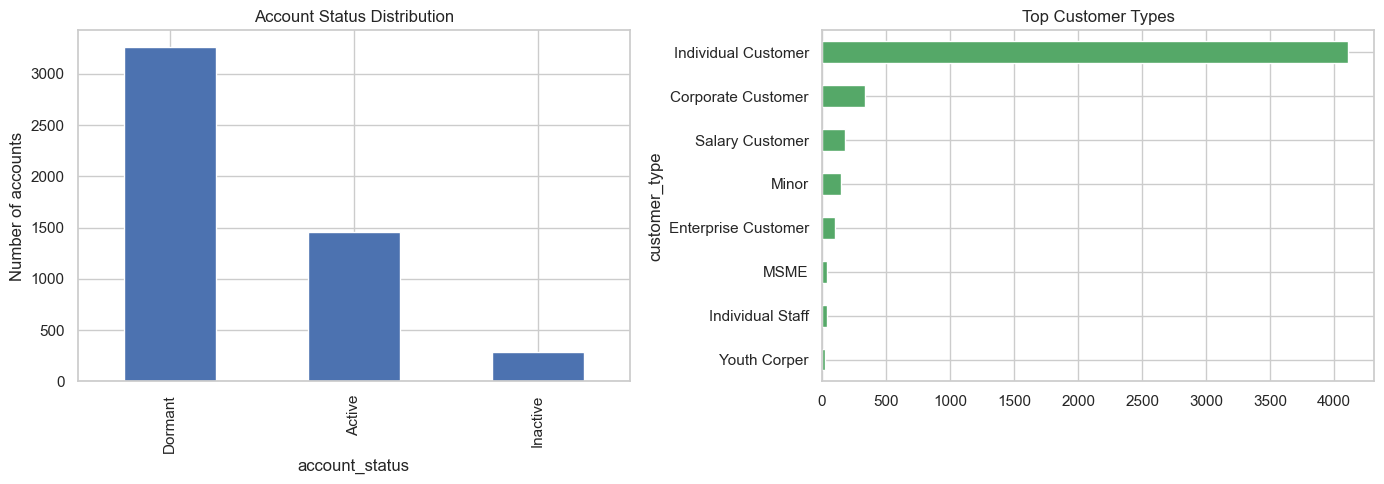

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

customers_clean["account_status"].value_counts().plot(kind="bar", ax=axes[0], color="#4C72B0")
axes[0].set_title("Account Status Distribution")
axes[0].set_ylabel("Number of accounts")

customers_clean["customer_type"].value_counts().head(8).plot(kind="barh", ax=axes[1], color="#55A868")
axes[1].set_title("Top Customer Types")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()


**65.2% of accounts are Dormant**, with only 29.1% Active
**Individual Customers** dominate the customer_type breakdown with 82.1%

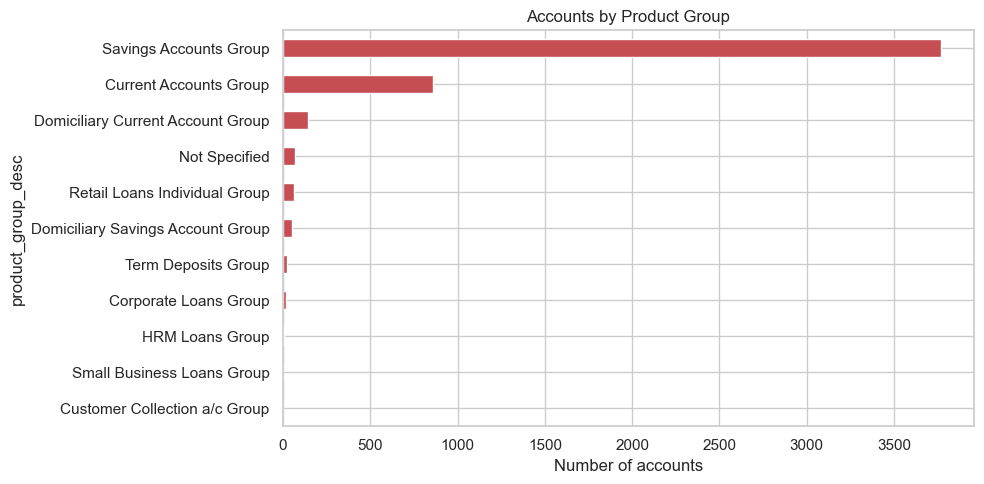

In [26]:
plt.figure(figsize=(10, 5))
customers_clean["product_group_desc"].value_counts().plot(kind="barh", color="#C44E52")
plt.title("Accounts by Product Group")
plt.xlabel("Number of accounts")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


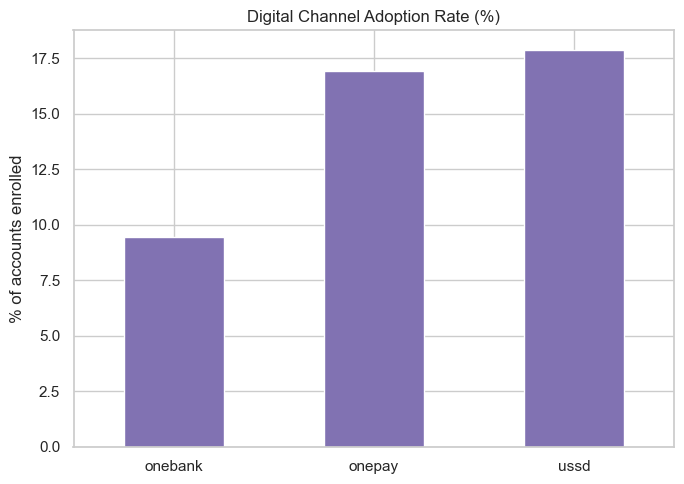

onebank     9.4
onepay     16.9
ussd       17.9
dtype: float64

In [27]:
# Digital channel adoption - what share of customers use each digital channel?
channel_adoption = customers_clean[["onebank", "onepay", "ussd"]].mean() * 100
channel_adoption.plot(kind="bar", color="#8172B2", figsize=(7, 5))
plt.title("Digital Channel Adoption Rate (%)")
plt.ylabel("% of accounts enrolled")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
channel_adoption.round(1)


Digital channel adoption is low across the board — each of `onebank`, `onepay` and `ussd`
sits well under half of the customer base, with `onepay` adoption the lowest. Combined with the
high dormancy rate above, this suggests digital enablement may be an area worth investigating
as a lever to reactivate dormant accounts.

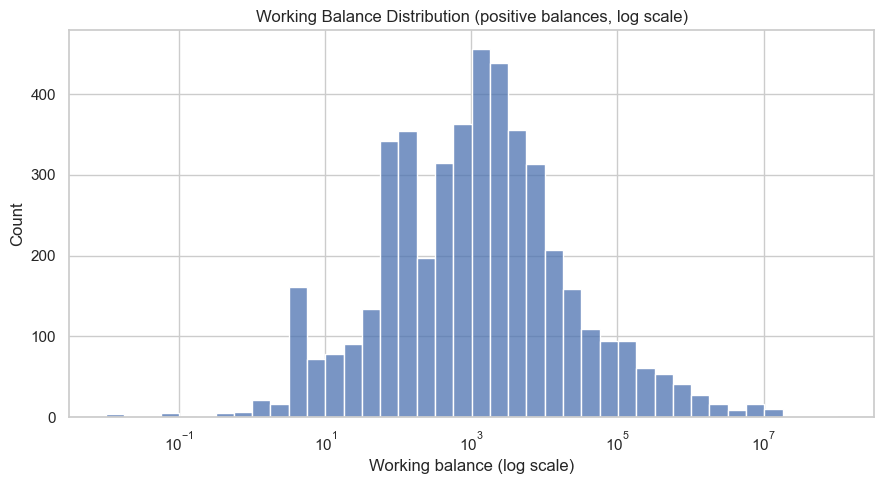

Accounts with balance <= 0: 363


In [28]:
plt.figure(figsize=(9, 5))
# Log scale to handle the extreme balance outliers without them swallowing the chart
sns.histplot(customers_clean.loc[customers_clean["workingbalance"] > 0, "workingbalance"],
             log_scale=True, bins=40, color="#4C72B0")
plt.title("Working Balance Distribution (positive balances, log scale)")
plt.xlabel("Working balance (log scale)")
plt.tight_layout()
plt.show()

print("Accounts with balance <= 0:", (customers_clean["workingbalance"] <= 0).sum())


## EDA - Transaction behavior

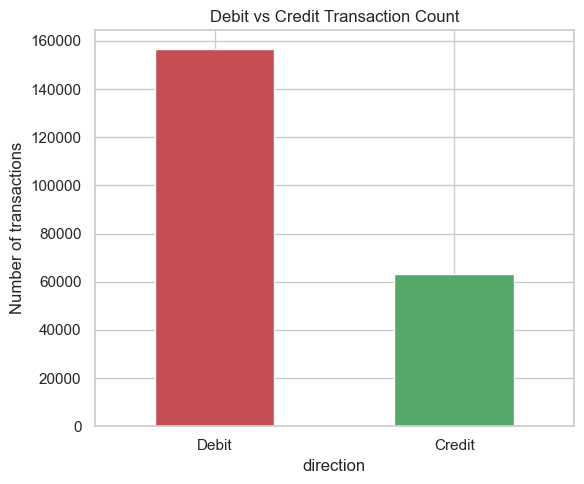

direction
Debit     71.2
Credit    28.8
Name: proportion, dtype: float64

In [29]:
plt.figure(figsize=(6, 5))
transactions_clean["direction"].value_counts().plot(kind="bar", color=["#C44E52", "#55A868"])
plt.title("Debit vs Credit Transaction Count")
plt.ylabel("Number of transactions")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

transactions_clean["direction"].value_counts(normalize=True).round(3) * 100


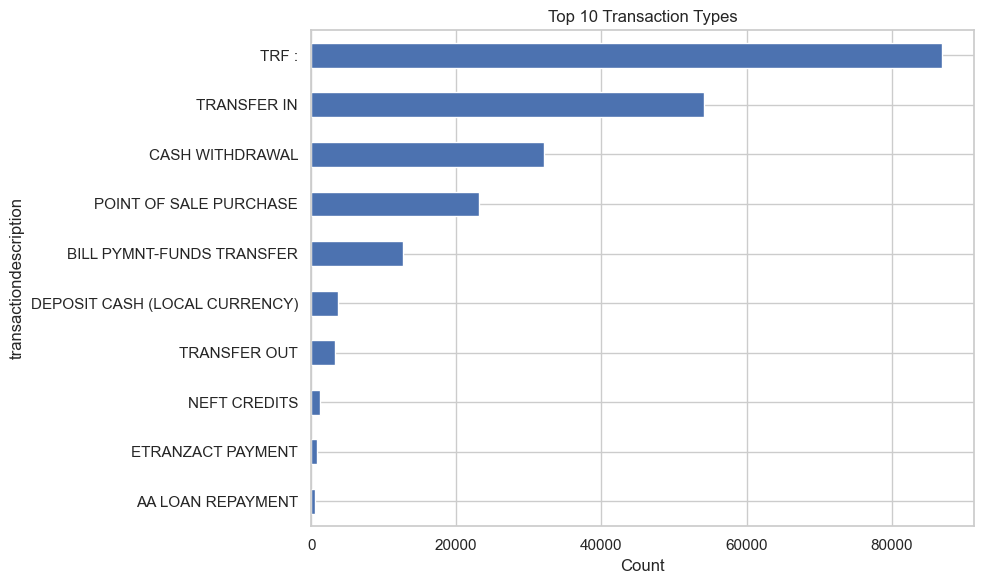

In [30]:
plt.figure(figsize=(10, 6))
transactions_clean["transactiondescription"].value_counts().head(10).plot(
    kind="barh", color="#4C72B0"
)
plt.title("Top 10 Transaction Types")
plt.xlabel("Count")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


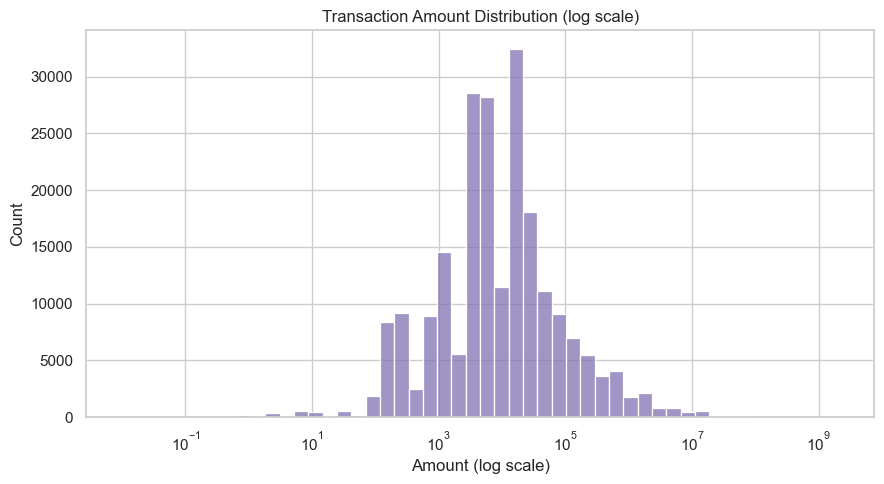

In [31]:
plt.figure(figsize=(9, 5))
sns.histplot(transactions_clean["AMOUNT_LCY"], log_scale=True, bins=50, color="#8172B2")
plt.title("Transaction Amount Distribution (log scale)")
plt.xlabel("Amount (log scale)")
plt.tight_layout()
plt.show()


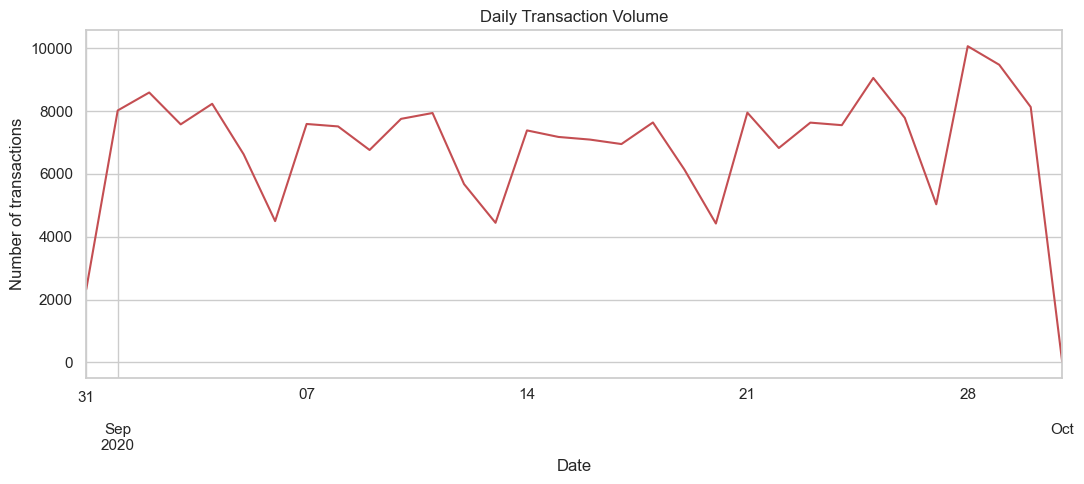

Date range covered: 2020-08-31 16:20:05 to 2020-10-01 05:54:21.997000


In [32]:
# Daily transaction volume over time
daily_volume = transactions_clean.set_index("Trans_timestamp").resample("D").size()

plt.figure(figsize=(11, 5))
daily_volume.plot(color="#C44E52")
plt.title("Daily Transaction Volume")
plt.ylabel("Number of transactions")
plt.xlabel("Date")
plt.tight_layout()
plt.show()

print("Date range covered:", transactions_clean["Trans_timestamp"].min(), "to", transactions_clean["Trans_timestamp"].max())


The data covers roughly **one month** (late Aug to early Oct 2020), not a full year

## EDA - Merged view (overlap subset only)

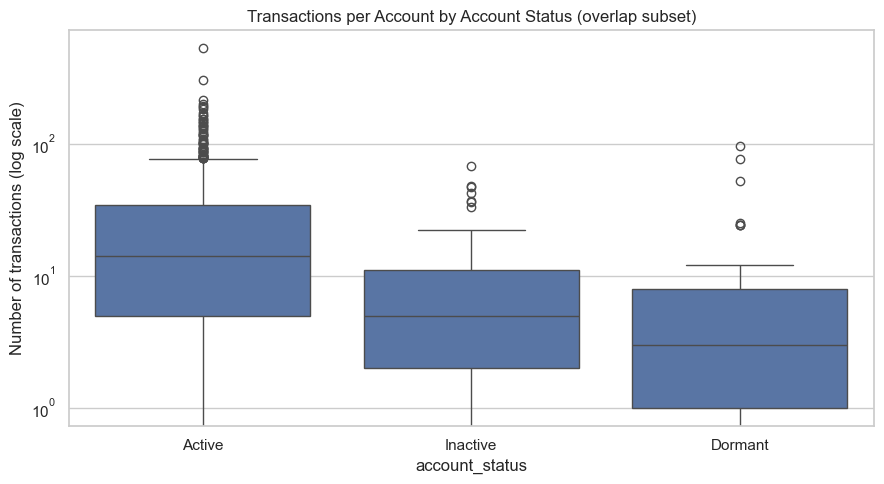

In [33]:
tx_per_account = merged.groupby("accountid").agg(n_transactions=("Trans_ID", "count"),total_amount=("AMOUNT_LCY", "sum"),).reset_index()

account_summary = customers_clean.merge(tx_per_account, on="accountid", how="inner")

plt.figure(figsize=(9, 5))
sns.boxplot(data=account_summary, x="account_status", y="n_transactions", color="#4C72B0")
plt.yscale("log")
plt.title("Transactions per Account by Account Status (overlap subset)")
plt.ylabel("Number of transactions (log scale)")
plt.tight_layout()
plt.show()

Active accounts clearly transact more — this confirms that activity
(not just status) is where revenue is generated. This supports prioritizing reactivation
campaigns specifically toward dormant accounts with partial engagement signals (e.g. accounts
that still have digital channels enrolled but low transaction count) as the easiest wins.

In [34]:
account_summary.groupby("customer_type")["n_transactions"].agg(["count", "mean", "median"]).sort_values("count", ascending=False).head(8)

,count,mean,median
customer_type,,,
Individual Customer,663,26.217195,13.0
Salary Customer,91,16.615385,11.0
Corporate Customer,51,17.039216,4.0
Enterprise Customer,16,21.312500,5.0
Minor,15,12.400000,5.0
Individual Staff,12,29.250000,13.5
MSME,11,19.181818,3.0
EMBASSY/HIGH COMMISSION,2,2.000000,2.0


## Key Insights

1. **Dormancy is the biggest revenue opportunity.** ~65% of accounts are dormant vs. ~29%
   active. Converting even 10-15% of dormant accounts to active would meaningfully grow
   transaction revenue without new customer acquisition cost.
2. **Low digital adoption is likely a driver of dormancy.** Enrollment in onebank/onepay/ussd
   sits well under 50% across the board, digital convenience correlates with engagement, so
   this is a practical, controllable lever.
3. **Active accounts transact significantly more than dormant/inactive ones**, confirming that
   account status is a real behavioral signal the bank can target, not just a label.
4. **Debit transactions dominate (71%)**  withdrawals, transfers and POS purchases - suggesting
   customers primarily use accounts for spending/cash access rather than saving or investment
   products, which may point to cross-sell opportunities (savings plans, fixed deposits).
5. *(Data note)* Only ~868 of ~5,000 customer accounts could be matched to transaction records,
   so the behavioral findings above are directional(based on the matched subset) and should be
   validated against the full customer base once the data linkage gap is resolved.

## Recommendations

1. **Launch a targeted dormant-account reactivation campaign**, prioritizing customers who still
   have digital channels enrolled, they're the warmest leads, already one step engaged.
2. **Push digital channel enrollment** (onebank/onepay/ussd) as a low-cost engagement driver,
   especially bundled with reactivation outreach.
3. **Cross-sell savings/investment products** to active, debit-heavy customers as they're already
   engaged but currently using the account mainly for spending, not growth products.
4. **Resolve the data linkage gap** between customer and transaction systems so future targeting
   can be based on the full customer base, not just the ~17% currently matchable.

## 11. Conclusion

This EDA cleaned both datasets, quantified their missingness, and most importantly
surfaced a significant data linkage gap between the customer and transaction files that limits
how much can be concluded from a merged view. Within those limits, the customer base skews
heavily dormant with low digital adoption, balances are highly skewed with some clearly
implausible extreme values, and transaction activity (dominated by transfers, withdrawals and
POS purchases) is concentrated in a minority of accounts over a one-month window.